<a href="https://colab.research.google.com/github/vitormankowskicorrea-lab/Estudo-Independente-III/blob/main/clima_collector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Coletor de Previsão do Tempo — API Open-Meteo
**Disciplina:** Programação para Ciência de Dados

**Objetivo:** coletar automaticamente a previsão de 7 dias de capitais brasileiras via API pública, tratar os dados com `pandas` e exportar em **CSV** e **JSON**.





## 1. Importações e configuração de logs

In [ ]:
import json
import logging
import time
from abc import ABC, abstractmethod
from datetime import datetime
from pathlib import Path
from typing import Any

import pandas as pd
import requests

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("clima")


## 2. Coleta de dados
`BaseCollector` é uma **classe abstrata**: encapsula a lógica HTTP (timeout, novas tentativas, erros) e define o contrato `collect()`.
Cada fonte de dados concreta herda dela e implementa apenas o "o quê" coletar (**polimorfismo**).

In [ ]:
class BaseCollector(ABC):
    """Classe abstrata: contrato de qualquer coletor e lógica HTTP reutilizável."""

    def __init__(self, timeout: int = 15, retries: int = 3) -> None:
        self._timeout = timeout
        self._retries = retries
        self._session = requests.Session()
        self._session.headers.update({"User-Agent": "projeto-academico-ciencia-de-dados"})

    def _get_json(self, url: str, params: dict[str, Any] | None = None) -> Any:
        """GET com novas tentativas; devolve o JSON convertido para objetos Python."""
        last_error: Exception | None = None
        for attempt in range(1, self._retries + 1):
            try:
                response = self._session.get(url, params=params, timeout=self._timeout)
                response.raise_for_status()      # levanta exceção para HTTP 4xx/5xx
                return response.json()
            except (requests.RequestException, json.JSONDecodeError) as exc:
                last_error = exc
                logger.warning("Tentativa %d/%d falhou: %s", attempt, self._retries, exc)
                time.sleep(1.5 * attempt)
        raise RuntimeError(f"Falha ao acessar {url}") from last_error

    @abstractmethod
    def collect(self) -> list[dict[str, Any]]:
        """Retorna uma lista de registros (dicionários) brutos."""


### 2.1 Coletor da Open-Meteo
A API devolve os dados em formato **colunar** (`{"time": [...], "temperature_2m_max": [...]}`).
O método `_fetch_city` transforma isso em uma lista de registros (uma linha por cidade/dia).

In [ ]:
class OpenMeteoCollector(BaseCollector):
    """Coleta a previsão diária de várias cidades na API Open-Meteo."""

    BASE_URL = "https://api.open-meteo.com/v1/forecast"
    DAILY_VARS = "temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max"

    # cidade -> (latitude, longitude)
    DEFAULT_CITIES = {
        "Porto Alegre": (-30.03, -51.23),
        "São Paulo": (-23.55, -46.63),
        "Rio de Janeiro": (-22.91, -43.17),
        "Brasília": (-15.79, -47.88),
        "Manaus": (-3.12, -60.02),
        "Recife": (-8.05, -34.88),
    }

    def __init__(self, cities: dict[str, tuple[float, float]] | None = None,
                 forecast_days: int = 7, **kwargs: Any) -> None:
        super().__init__(**kwargs)
        self._cities = cities or self.DEFAULT_CITIES
        self._forecast_days = forecast_days

    def _fetch_city(self, name: str, lat: float, lon: float) -> list[dict[str, Any]]:
        """Consulta uma cidade e converte o formato colunar da API em registros (linhas)."""
        params = {
            "latitude": lat,
            "longitude": lon,
            "daily": self.DAILY_VARS,
            "timezone": "America/Sao_Paulo",
            "forecast_days": self._forecast_days,
        }
        daily = self._get_json(self.BASE_URL, params=params)["daily"]
        # A API devolve {"time": [...], "temperature_2m_max": [...], ...}
        # Aqui "transpomos" para uma lista de dicts, um por dia.
        return [
            {"cidade": name, "latitude": lat, "longitude": lon,
             **{campo: valores[i] for campo, valores in daily.items()}}
            for i in range(len(daily["time"]))
        ]

    def collect(self) -> list[dict[str, Any]]:
        records: list[dict[str, Any]] = []
        for name, (lat, lon) in self._cities.items():
            try:
                logger.info("Consultando %s...", name)
                records.extend(self._fetch_city(name, lat, lon))
            except (RuntimeError, KeyError) as exc:
                # Uma cidade com erro não derruba a coleta das demais
                logger.error("Cidade ignorada (%s): %s", name, exc)
        if not records:
            raise RuntimeError("Nenhuma cidade pôde ser coletada.")
        logger.info("%d registros brutos coletados.", len(records))
        return records


## 3. Tratamento dos dados
`ClimaProcessor` limpa textos, converte tipos numéricos, valida datas e cria colunas derivadas (**amplitude térmica** e **condição de chuva**).

In [ ]:
class ClimaProcessor:
    """Limpa, converte tipos e cria colunas derivadas."""

    COLUMNS = {
        "cidade": "cidade",
        "latitude": "latitude",
        "longitude": "longitude",
        "time": "data",
        "temperature_2m_max": "temp_max_c",
        "temperature_2m_min": "temp_min_c",
        "precipitation_sum": "chuva_mm",
        "wind_speed_10m_max": "vento_max_kmh",
    }
    NUMERIC = ["latitude", "longitude", "temp_max_c", "temp_min_c", "chuva_mm", "vento_max_kmh"]

    def process(self, raw: list[dict[str, Any]]) -> pd.DataFrame:
        if not raw:
            raise ValueError("Nenhum dado para processar.")

        df = pd.DataFrame(raw).reindex(columns=list(self.COLUMNS)).rename(columns=self.COLUMNS)

        # Texto: remove espaços extras
        df["cidade"] = df["cidade"].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

        # Números: garante tipo numérico (valores inválidos viram NaN)
        for col in self.NUMERIC:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        # Data: valida o formato e mantém como texto AAAA-MM-DD
        df["data"] = pd.to_datetime(df["data"], errors="coerce").dt.strftime("%Y-%m-%d")

        # Colunas derivadas (feature engineering)
        df["amplitude_termica_c"] = (df["temp_max_c"] - df["temp_min_c"]).round(1)
        df["condicao"] = pd.cut(
            df["chuva_mm"],
            bins=[-float("inf"), 1, 10, float("inf")],
            labels=["Sem chuva", "Chuva", "Chuva forte"],
            right=False,
        ).astype(object)

        df["coletado_em"] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

        df = (
            df.dropna(subset=["data"])
              .drop_duplicates(subset=["cidade", "data"])
              .sort_values(["cidade", "data"])
              .reset_index(drop=True)
        )
        logger.info("DataFrame final: %d linhas x %d colunas.", *df.shape)
        return df


## 4. Exportação (CSV e JSON)

In [ ]:
class DataExporter:
    """Salva o DataFrame em CSV e JSON."""

    def __init__(self, output_dir: str = "saida") -> None:
        self._dir = Path(output_dir)
        self._dir.mkdir(parents=True, exist_ok=True)

    def to_csv(self, df: pd.DataFrame, name: str = "previsao_clima.csv") -> Path:
        path = self._dir / name
        df.to_csv(path, index=False, encoding="utf-8-sig")   # utf-8-sig: acentos corretos no Excel
        return path

    def to_json(self, df: pd.DataFrame, name: str = "previsao_clima.json") -> Path:
        path = self._dir / name
        # NaN/NA -> None, que vira `null` no JSON
        records = df.astype(object).where(df.notna(), None).to_dict(orient="records")
        with open(path, "w", encoding="utf-8") as f:
            json.dump(records, f, ensure_ascii=False, indent=2)
        return path


## 5. Pipeline (orquestração)
Une as três etapas por **composição** de objetos. O `try-except` fica centralizado aqui.

In [ ]:
class ClimaPipeline:
    """Une coleta -> tratamento -> exportação (composição de objetos)."""

    def __init__(self, collector: BaseCollector, processor: ClimaProcessor, exporter: DataExporter) -> None:
        self._collector = collector
        self._processor = processor
        self._exporter = exporter

    def run(self) -> pd.DataFrame | None:
        try:
            raw = self._collector.collect()
            df = self._processor.process(raw)
            csv_path = self._exporter.to_csv(df)
            json_path = self._exporter.to_json(df)
            logger.info("Arquivos gerados: %s | %s", csv_path, json_path)
            return df
        except (RuntimeError, ValueError, OSError) as exc:
            logger.error("Pipeline interrompido: %s", exc)
            return None


## 6. Execução

In [ ]:
pipeline = ClimaPipeline(
    collector=OpenMeteoCollector(forecast_days=7),
    processor=ClimaProcessor(),
    exporter=DataExporter("saida"),
)

df = pipeline.run()
df.head(10) if df is not None else print("Falha na coleta. Verifique os logs acima.")

ERROR:clima:Cidade ignorada (Porto Alegre): Falha ao acessar https://api.open-meteo.com/v1/forecast


,cidade,latitude,longitude,data,temp_max_c,temp_min_c,chuva_mm,vento_max_kmh,amplitude_termica_c,condicao,coletado_em
0,Brasília,-15.79,-47.88,2026-11-14,26.9,17.9,1.6,8.1,9.0,Chuva,2026-11-14 16:39:50
1,Brasília,-15.79,-47.88,2026-11-15,26.9,18.3,2.8,15.9,8.6,Chuva,2026-11-14 16:39:50
2,Brasília,-15.79,-47.88,2026-11-16,24.7,19.3,7.2,14.0,5.4,Chuva,2026-11-14 16:39:50
3,Brasília,-15.79,-47.88,2026-11-17,22.7,19.2,11.6,19.1,3.5,Chuva forte,2026-11-14 16:39:50
4,Brasília,-15.79,-47.88,2026-11-18,24.4,18.9,6.6,17.3,5.5,Chuva,2026-11-14 16:39:50
5,Brasília,-15.79,-47.88,2026-11-19,25.4,19.5,8.3,15.8,5.9,Chuva,2026-11-14 16:39:50
6,Brasília,-15.79,-47.88,2026-11-20,26.9,19.8,0.7,17.3,7.1,Sem chuva,2026-11-14 16:39:50
7,Manaus,-3.12,-60.02,2026-11-14,32.3,26.0,0.9,12.3,6.3,Sem chuva,2026-11-14 16:39:50
8,Manaus,-3.12,-60.02,2026-11-15,32.9,27.5,2.2,12.3,5.4,Chuva,2026-11-14 16:39:50
9,Manaus,-3.12,-60.02,2026-11-16,31.5,24.1,7.5,13.2,7.4,Chuva,2026-11-14 16:39:50


## 7. Conferindo os arquivos gerados

In [ ]:
import os
print("Arquivos em 'saida/':", os.listdir("saida"))

print("\n--- CSV (3 primeiras linhas) ---")
with open("saida/previsao_clima.csv", encoding="utf-8-sig") as f:
    for _ in range(4):          # cabeçalho + 3 linhas
        print(f.readline().rstrip())

Arquivos em 'saida/': ['previsao_clima.json', 'previsao_clima.csv']

--- CSV (3 primeiras linhas) ---
cidade,latitude,longitude,data,temp_max_c,temp_min_c,chuva_mm,vento_max_kmh,amplitude_termica_c,condicao,coletado_em
Brasília,-15.79,-47.88,2026-11-14,26.9,17.9,1.6,8.1,9.0,Chuva,2026-11-14 16:39:50
Brasília,-15.79,-47.88,2026-11-15,26.9,18.3,2.8,15.9,8.6,Chuva,2026-11-14 16:39:50
Brasília,-15.79,-47.88,2026-11-16,24.7,19.3,7.2,14.0,5.4,Chuva,2026-11-14 16:39:50


In [ ]:
import json

with open("saida/previsao_clima.json", encoding="utf-8") as f:
    dados = json.load(f)

print(f"Total de registros no JSON: {len(dados)}")
print(json.dumps(dados[:3], ensure_ascii=False, indent=2))

Total de registros no JSON: 35
[
  {
    "cidade": "Brasília",
    "latitude": -15.79,
    "longitude": -47.88,
    "data": "2026-11-14",
    "temp_max_c": 26.9,
    "temp_min_c": 17.9,
    "chuva_mm": 1.6,
    "vento_max_kmh": 8.1,
    "amplitude_termica_c": 9.0,
    "condicao": "Chuva",
    "coletado_em": "2026-11-14 16:39:50"
  },
  {
    "cidade": "Brasília",
    "latitude": -15.79,
    "longitude": -47.88,
    "data": "2026-11-15",
    "temp_max_c": 26.9,
    "temp_min_c": 18.3,
    "chuva_mm": 2.8,
    "vento_max_kmh": 15.9,
    "amplitude_termica_c": 8.6,
    "condicao": "Chuva",
    "coletado_em": "2026-11-14 16:39:50"
  },
  {
    "cidade": "Brasília",
    "latitude": -15.79,
    "longitude": -47.88,
    "data": "2026-11-16",
    "temp_max_c": 24.7,
    "temp_min_c": 19.3,
    "chuva_mm": 7.2,
    "vento_max_kmh": 14.0,
    "amplitude_termica_c": 5.4,
    "condicao": "Chuva",
    "coletado_em": "2026-11-14 16:39:50"
  }
]


## 8. Visualização rápida


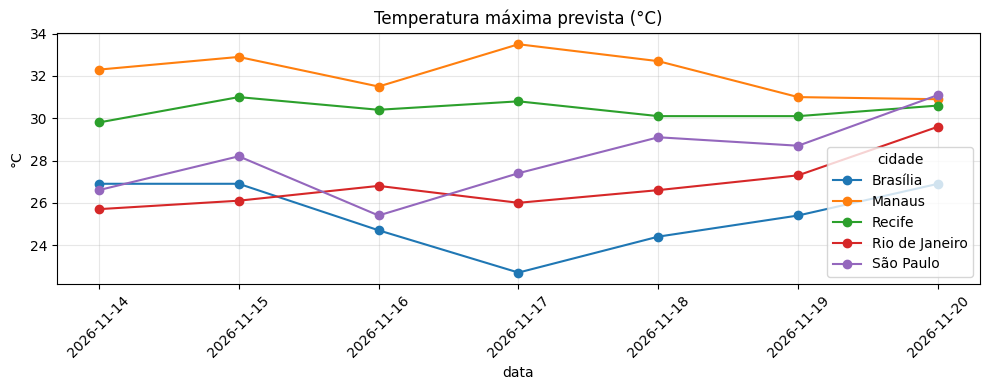

In [ ]:
import matplotlib.pyplot as plt

if df is not None:
    tabela = df.pivot(index="data", columns="cidade", values="temp_max_c")
    tabela.plot(figsize=(10, 4), marker="o", title="Temperatura máxima prevista (°C)")
    plt.ylabel("°C")
    plt.xticks(rotation=45)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 9. Conclusão
- Coleta automática via **API REST pública** (`requests` + JSON)
- Código modular em **POO** (abstração, herança, encapsulamento, composição)
- Tratamento e *feature engineering* com **pandas**
- Exportação em **CSV** e **JSON**, com tratamento de exceções